# Kernel methods

## Motivation: the radial basis function

```{admonition} Example
We look at a synthetic dataset that is badly suited to k-means,
and 'make' it suitable with a trick.
```

In [1]:
import numpy as np
import scipy.stats as st

# craft synthetic data:
def rings(n, radius=(8, 9)):
    rs = st.multivariate_normal(mean=radius[0]+np.ptp(radius),
                                cov=np.ptp(radius)/2
                               ).rvs(size=n)
    phis = st.uniform.rvs(size=n) * 2 * np.pi
    x, y = np.cos(phis), np.sin(phis)
    return (rs * np.stack([x, y])).T

n = 2000
sample = rings(n)
secondsample = st.multivariate_normal.rvs(mean=[0,0], cov=np.eye(2), size=n)
sample = np.concatenate([sample, secondsample])

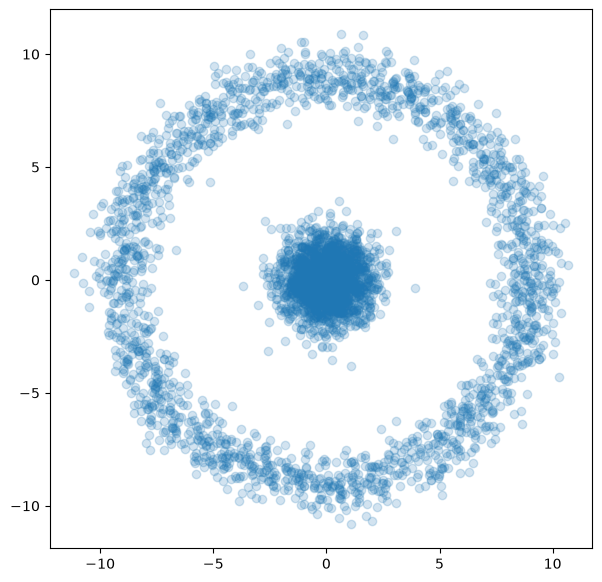

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=0.2)
plt.show()

### A geometric transformation

In [3]:
# this produces the same as meshgrid, but is more explicit:
ticks = 20
frames = 70
x = np.outer(np.linspace(-12, 12, ticks), np.ones(ticks))
y = x.copy().T # transpose
rbf_surface_in_time =   np.linspace(0, 1, frames).reshape(1, 1, -1) \
                      * ((x**2 + y**2).reshape(ticks, ticks, 1))

In [4]:
import matplotlib.animation as animation
from IPython import display as ipydisplay
import io, base64

def init(ax):
    ax.clear()
    ax.set_xlim(-12, 12)
    ax.set_ylim(-12, 12)
    ax.set_zlim( -1, 350)
    ax.set_zticklabels([])
    
def update_surface(i, ax):
    init(ax)
    ax.view_init(10, 15+i)
    ax.plot_surface(x, y, rbf_surface_in_time[:,:,i])

def update_data(i, ax):
    init(ax)
    ax.view_init(10, 15+i)
    ax.scatter(sample[:,0], sample[:,1],
               2*i/frames * (sample[:,0]**2 + sample[:,1]**2),
               marker='.', s=50)
    
def plot_ani(func=update_surface):
    fig = plt.figure(figsize=(7, 7))
    fig.set_size_inches(9, 9)
    ax = plt.axes(projection='3d')
    ani = animation.FuncAnimation(fig, func, fargs=(ax,), interval=100,
                              frames=np.hstack([np.arange(frames),np.arange(frames)[::-1]]))
    video = ani.to_html5_video()
    # Also output the last frame as a PNG: the web export shows the video,
    # the PDF export (which cannot do HTML) uses the still image.
    png = io.BytesIO()
    fig.savefig(png, format='png')
    ipydisplay.display({'text/html': video,
                        'image/png': base64.b64encode(png.getvalue()).decode('ascii')},
                       raw=True)
    plt.close()

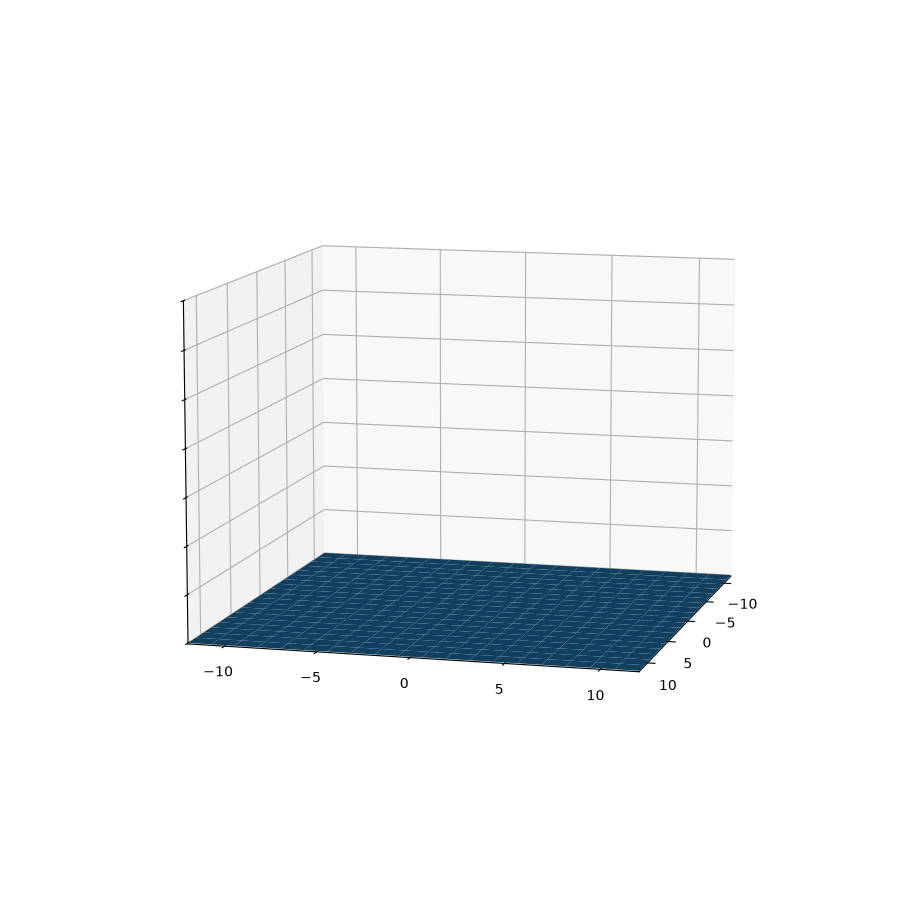

In [5]:
plot_ani(update_surface)

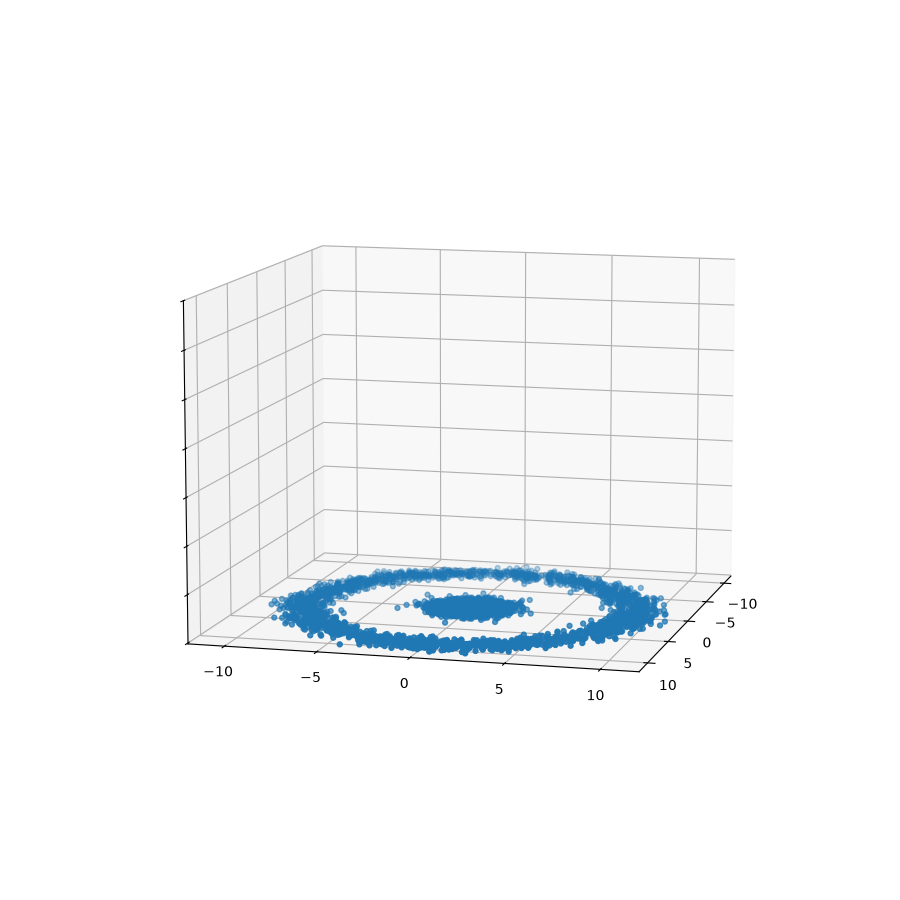

In [6]:
plot_ani(update_data)

Data transformed in this way can now be clustered with 2-means!

### k-means in the transformed space

In [7]:
def radial(x, y):
    """Squared distance from (x,y) to the origin: a single coordinate
    of the feature map φ, which we introduce in general further below."""
    return x**2 + y**2

xs, ys = sample[:,0], sample[:,1] 
zs = radial(xs, ys)

from sklearn.cluster import KMeans
kmeans_fit = KMeans(n_clusters=2, n_init=1).fit(np.stack([xs,ys,zs]).T)

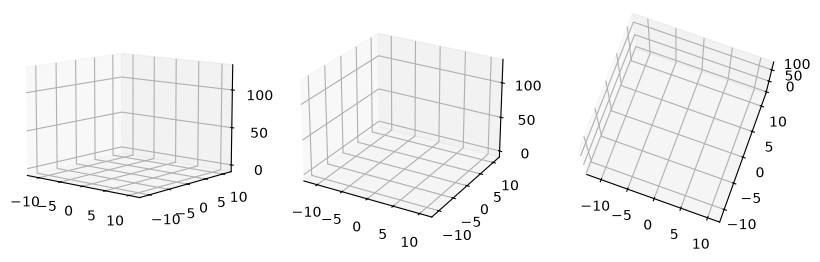

In [8]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(331, projection='3d')
ax2 = fig.add_subplot(332, projection='3d')
ax3 = fig.add_subplot(333, projection='3d')
for axis in (ax, ax2, ax3):
    axis.scatter(xs, ys, zs,
                 alpha=0.02, c=kmeans_fit.labels_,
                 cmap='brg')
ax.view_init(elev=10., azim=-50)
ax2.view_init(elev=25., azim=-60)
ax3.view_init(elev=75., azim=-70)
plt.show()

We can also run only the k-means computation in this larger space (with the radial feature $x^2+y^2$), then carry the labels back and show them in our 'old' two-dimensional plot:

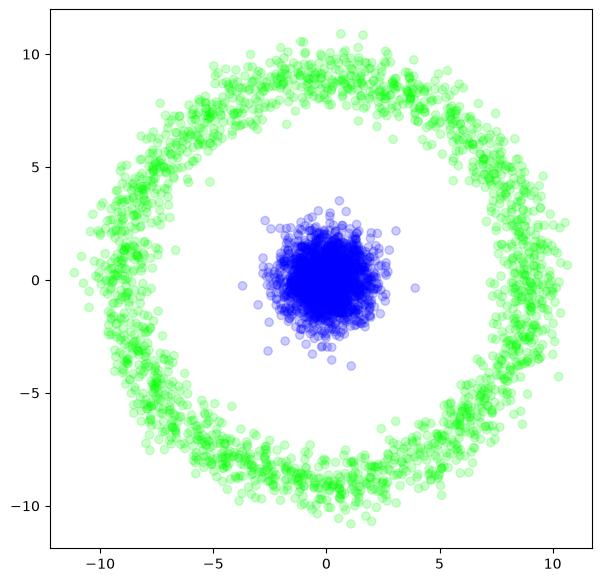

In [9]:
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=0.2,
           c=kmeans_fit.labels_,
           cmap='brg')
plt.show()

### What we actually needed

The k-means algorithm measures *distances* all the time. It is therefore invariant under translation and rotation. And if we do not transform our data at all, but merely measure distances with the notion of distance from the transformed space, that could, depending on the transformation, be less expensive to compute.

Other algorithms, too – k-nearest neighbours and support vector machines, for instance (neither of which we have discussed) – rest on nothing but measurements of distance.

## Describing data by distances

```{admonition} Example
Two points $A, B$ in the plane can be described by their coordinates.
Alternatively one can remember a single datum, the distance $d(A, B)$, and from it recover the dataset $(A, B)$ up to translation and rotation.
```

```{admonition} Example
Three points $A, B, C$ in three-dimensional space can be described by their coordinates.
Alternatively one can remember the datum of the distances $d(A, B),\ d(B, C),\ d(A, C)$ and from it recover the dataset $(A, B, C)$ up to translation and rotation.
```

The kernel trick is now to describe the data $x_i$ not by the symmetric matrix $d(x_i, x_j)$ but by some other function $\kappa(x_i, x_j)$ that plays the same role as a measurement of distance in a transformed coordinate system.

The Euclidean distance is

$$
d(a,b) = \lVert b - a \rVert = \sqrt{\langle b-a , b-a \rangle} = \sqrt{(b-a)^T (b-a)}
$$

If one applies a linear transformation $M$ to the data, what one computes is

$$
d(Ma, Mb)^2 = \lVert Mb - Ma \rVert^2 = \lVert M(b - a) \rVert^2 = \langle M(b-a), M(b-a) \rangle = (b-a)^T M^T M (b-a)
$$

so that for a measurement of distance in the transformed space we do not actually have to compute $Ma$ and $Mb$ at all – 'only' apply $M^TM$, rather often. With luck, that is the easier job.

Often the inner product $\langle a, b\rangle$ itself is a good notion of distance too, or $\langle Ma, Mb\rangle = b^T M^TM a$.

An aside, by way of explanation: we can also compute
$$
{\lVert b-a \rVert}^2 = \langle b-a, b-a\rangle = \langle b,b\rangle - 2\langle a, b\rangle + \langle a, a\rangle = {\lVert a \rVert}^2 + {\lVert b \rVert}^2 -2\langle a, b\rangle
$$
which for normalised vectors $a,b$ (that is, ${\lVert a \rVert} = 1$ and ${\lVert b \rVert} = 1$) shows a close relationship between $\langle a, b\rangle = {\lVert a \rVert}{\lVert b \rVert}\cos(\measuredangle(a,b)) = \cos(\measuredangle(a,b))$ and $d(a,b) = \sqrt{2}\sqrt{1-\langle a, b\rangle}$.

One now abstracts away from the linear situation and allows an arbitrary map into a vector space with an inner product.

## Kernels

```{admonition} Definition
A map $\kappa \colon \mathcal{X} \times \mathcal{X} \to \mathbb{R}$ is called a **kernel** if there is a vector space $F$ with an inner product $\langle,\rangle$ together with a map $\phi \colon \mathcal{X} \to F$ such that $\kappa(x,y) = \langle \phi(x),\ \phi(y) \rangle$ holds for all $x,y \in \mathcal{X}$.
The vector space $F$ is called the **feature space** and $\phi$ the feature map.
```

With a kernel one need not know the space $F$ and the map $\phi$ at all, because for symmetric positive definite functions $\kappa \colon \mathcal{X} \times \mathcal{X} \to \mathbb{R}$ there is always a construction of a $\phi \colon \mathcal{X} \to F$ that represents $\kappa$ as a kernel (*Mercer's theorem*).

One also speaks of a **Mercer** kernel; more generally, functions $\kappa$ that are not necessarily positive definite or symmetric are also called **kernel functions**.

One speaks of the **kernel method** in general when an algorithm is reformulated so that it works only with the inner products of the feature vectors, and these are then replaced by a kernel function.

### Gaussian kernels

```{admonition} Definition
Kernels of the form

$$
\kappa(x,y) = e^{\left(-\dfrac{\lVert x - y \rVert^2}{2\sigma^2}\right)}
$$

are called **Gaussian kernels** with parameter $\gamma = \frac{1}{2\sigma^2}$.
Alternatively one speaks of the **squared exponential kernel**, the **quadratic exponential kernel** or the **radial basis function kernel**.
```

Note that we need not compare $(x-\mu)$ with $(y-\mu)$ here, because the two have the same difference $x-y$. The usual normalisation drops out as well, because we are dealing not with probabilities but with a notion of distance.

In [10]:
from sklearn.metrics.pairwise import rbf_kernel

k = rbf_kernel(sample, gamma=None)
# from the scikit-learn documentation:
# gamma: If None, defaults to 1.0 / n_features.

k

array([[1.00000000e+00, 4.13904520e-58, 2.16272228e-01, ...,
        1.22811834e-23, 2.13172511e-14, 5.18538063e-21],
       [4.13904520e-58, 1.00000000e+00, 1.21371818e-57, ...,
        4.35762550e-19, 2.06913343e-19, 2.23830019e-21],
       [2.16272228e-01, 1.21371818e-57, 1.00000000e+00, ...,
        1.19980400e-19, 2.05065431e-12, 4.27055216e-17],
       ...,
       [1.22811834e-23, 4.35762550e-19, 1.19980400e-19, ...,
        1.00000000e+00, 1.64084897e-02, 7.84350348e-01],
       [2.13172511e-14, 2.06913343e-19, 2.05065431e-12, ...,
        1.64084897e-02, 1.00000000e+00, 3.60038828e-02],
       [5.18538063e-21, 2.23830019e-21, 4.27055216e-17, ...,
        7.84350348e-01, 3.60038828e-02, 1.00000000e+00]],
      shape=(4000, 4000))

But what does one do with the kernel?

Linear regression with ridge regularisation, for instance:

In [11]:
from sklearn.kernel_ridge import KernelRidge

# target variable is #cluster,
# given how we created the sample, it simply is:
y = np.hstack([np.zeros(len(sample)//2),np.ones(len(sample)//2)])

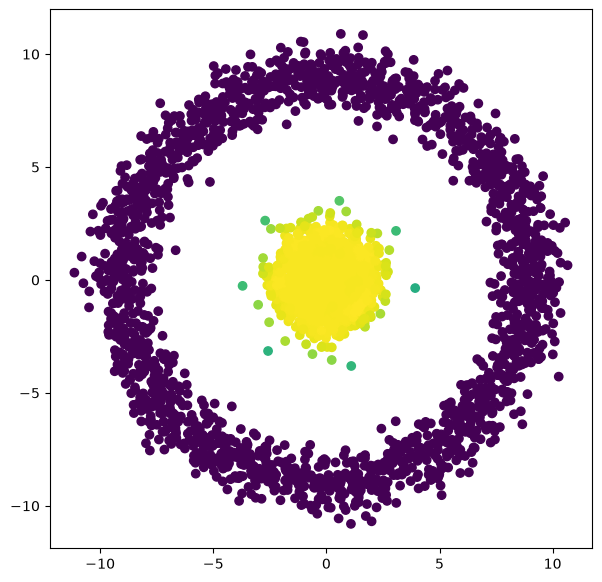

In [12]:
clf = KernelRidge(kernel="precomputed")

clf.fit(k, y)
y_pred = clf.predict(k)

fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], c=y_pred)
plt.show()

## Kernel PCA

Principal component analysis computes the eigenvectors of the covariance matrix. One can also transform the data nonlinearly first – or else use the correspondingly transformed covariance matrix.

In [13]:
from sklearn.decomposition import PCA, KernelPCA

pca = PCA(n_components=2)
kernel_pca = KernelPCA(
    n_components=None, kernel="rbf", gamma=0.2, alpha=2.5
)
# these parameters gamma, alpha needed some manual tweaking!

In [14]:
sample_pca = pca.fit_transform(sample)

In [15]:
# The following may need more than 16 GB of RAM,
# if the sample is large, so we're not going there:
#sample_kernel_pca = kernel_pca.fit_transform(sample)

# Keep it calm, train_size=2000 suffices:
from sklearn.model_selection import train_test_split
smaller_sample, remainder_sample, smaller_y, remainder_y \
  = train_test_split(sample, y_pred, train_size=2000)

sample_kernel_pca = kernel_pca.fit_transform(smaller_sample)

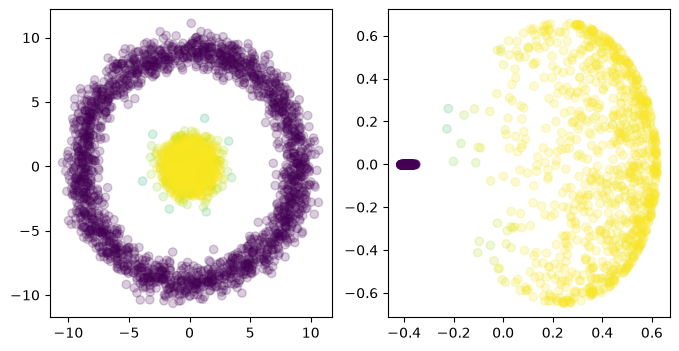

In [16]:
fig, axs = plt.subplots(ncols = 2, figsize=(8,4))
axs[0].scatter(sample_pca[:,0], sample_pca[:,1],
               c=y_pred, alpha=0.2)
axs[1].scatter(sample_kernel_pca[:,0], sample_kernel_pca[:,1],
               c=smaller_y, alpha=0.2)
plt.show()

Strictly speaking, kernel PCA first increases the number of dimensions (with the nonlinear feature map), then transforms them linearly onto principal components, so that unimportant dimensions can be thrown away again. The first principal component in the feature space no longer corresponds to a straight line in the original observation space but to a nonlinear curve.